In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']  
plt.rcParams['axes.unicode_minus'] = False   

In [3]:
df = pd.read_excel("testdata.xls", sheet_name = 'orignal_data')
df.head() 

,序号,性别,身份证号,是否吸烟,是否饮酒,开始从事某工作年份,体检年份,淋巴细胞计数,白细胞计数,细胞其它值,血小板计数
0,1,女,****1982080000,否,否,2009年,2017,2.4,8.5,NaN,248.0
1,2,女,****1984110000,否,否,2015年,2017,1.8,5.8,NaN,300.0
2,3,男,****1983060000,否,否,2013年,2017,2.0,5.6,NaN,195.0
3,4,男,****1985040000,否,否,2014年,2017,2.5,6.6,NaN,252.0
4,5,男,****1986040000,否,否,2014年,2017,1.3,5.2,NaN,169.0


In [4]:
df.dtypes

序号             int64
性别               str
身份证号             str
是否吸烟             str
是否饮酒             str
开始从事某工作年份     object
体检年份          object
淋巴细胞计数       float64
白细胞计数        float64
细胞其它值        float64
血小板计数        float64
dtype: object

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1234 entries, 0 to 1233
Data columns (total 11 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   序号         1234 non-null   int64  
 1   性别         1234 non-null   str    
 2   身份证号       1162 non-null   str    
 3   是否吸烟       1232 non-null   str    
 4   是否饮酒       1232 non-null   str    
 5   开始从事某工作年份  1231 non-null   object 
 6   体检年份       1123 non-null   object 
 7   淋巴细胞计数     1112 non-null   float64
 8   白细胞计数      1112 non-null   float64
 9   细胞其它值      0 non-null      float64
 10  血小板计数      1030 non-null   float64
dtypes: float64(4), int64(1), object(2), str(4)
memory usage: 106.2+ KB


In [7]:
df.isnull().sum()

序号              0
性别              0
身份证号           72
是否吸烟            2
是否饮酒            2
开始从事某工作年份       3
体检年份          111
淋巴细胞计数        122
白细胞计数         122
细胞其它值        1234
血小板计数         204
dtype: int64

In [8]:
df.dropna(axis = 1, how = 'all', inplace = True)
df.head()

,序号,性别,身份证号,是否吸烟,是否饮酒,开始从事某工作年份,体检年份,淋巴细胞计数,白细胞计数,血小板计数
0,1,女,****1982080000,否,否,2009年,2017,2.4,8.5,248.0
1,2,女,****1984110000,否,否,2015年,2017,1.8,5.8,300.0
2,3,男,****1983060000,否,否,2013年,2017,2.0,5.6,195.0
3,4,男,****1985040000,否,否,2014年,2017,2.5,6.6,252.0
4,5,男,****1986040000,否,否,2014年,2017,1.3,5.2,169.0


In [9]:
df.dropna(how = 'any', subset = ['身份证号'], inplace = True)
df.isnull().sum()

序号             0
性别             0
身份证号           0
是否吸烟           2
是否饮酒           2
开始从事某工作年份      3
体检年份          93
淋巴细胞计数       105
白细胞计数        105
血小板计数        182
dtype: int64

In [10]:
df.开始从事某工作年份 = df.开始从事某工作年份.str[0:4]
df.rename(columns = {"开始从事某工作年份": "参加工作时间"}, inplace = True)
df.head()

,序号,性别,身份证号,是否吸烟,是否饮酒,参加工作时间,体检年份,淋巴细胞计数,白细胞计数,血小板计数
0,1,女,****1982080000,否,否,2009,2017,2.4,8.5,248.0
1,2,女,****1984110000,否,否,2015,2017,1.8,5.8,300.0
2,3,男,****1983060000,否,否,2013,2017,2.0,5.6,195.0
3,4,男,****1985040000,否,否,2014,2017,2.5,6.6,252.0
4,5,男,****1986040000,否,否,2014,2017,1.3,5.2,169.0


In [15]:
df1 = df.dropna(subset = ['参加工作时间'], how = 'any')
df1.isnull().sum()

序号          0
性别          0
身份证号        0
是否吸烟        2
是否饮酒        2
参加工作时间      0
体检年份       38
淋巴细胞计数     41
白细胞计数      41
血小板计数     112
dtype: int64

In [16]:
df2 = df1.dropna(subset = ['体检年份'], how = 'any')
df2.isnull().sum()

序号         0
性别         0
身份证号       0
是否吸烟       1
是否饮酒       1
参加工作时间     0
体检年份       0
淋巴细胞计数     5
白细胞计数      5
血小板计数     74
dtype: int64

In [17]:
df2.dtypes

序号          int64
性别            str
身份证号          str
是否吸烟          str
是否饮酒          str
参加工作时间     object
体检年份       object
淋巴细胞计数    float64
白细胞计数     float64
血小板计数     float64
dtype: object

In [18]:
data = df2.copy() 
data.参加工作时间 = data.参加工作时间.astype('int64')
# 首先将体检年份转换为 str 类型
data['体检年份'] = data.体检年份.astype('str')
# 取前 4 位值之后再将体检年份转换为 int64 类型
data.体检年份 = data.体检年份.str[0:4].astype("int64")
# 取身份证的第 4 位-第 7 位,并转换为 int64 类型
data['出生年份'] = data.身份证号.str[4:8].astype('int64')
data.head()

,序号,性别,身份证号,是否吸烟,是否饮酒,参加工作时间,体检年份,淋巴细胞计数,白细胞计数,血小板计数,出生年份
0,1,女,****1982080000,否,否,2009,2017,2.4,8.5,248.0,1982
1,2,女,****1984110000,否,否,2015,2017,1.8,5.8,300.0,1984
2,3,男,****1983060000,否,否,2013,2017,2.0,5.6,195.0,1983
3,4,男,****1985040000,否,否,2014,2017,2.5,6.6,252.0,1985
4,5,男,****1986040000,否,否,2014,2017,1.3,5.2,169.0,1986


In [19]:
data = data.eval('工龄 = 体检年份 - 参加工作时间')
data = data.eval('年龄 = 体检年份 - 出生年份')
data.head()

,序号,性别,身份证号,是否吸烟,是否饮酒,参加工作时间,体检年份,淋巴细胞计数,白细胞计数,血小板计数,出生年份,工龄,年龄
0,1,女,****1982080000,否,否,2009,2017,2.4,8.5,248.0,1982,8,35
1,2,女,****1984110000,否,否,2015,2017,1.8,5.8,300.0,1984,2,33
2,3,男,****1983060000,否,否,2013,2017,2.0,5.6,195.0,1983,4,34
3,4,男,****1985040000,否,否,2014,2017,2.5,6.6,252.0,1985,3,32
4,5,男,****1986040000,否,否,2014,2017,1.3,5.2,169.0,1986,3,31


In [21]:
mean = data.groupby("性别")["白细胞计数"].mean()
mean

性别
女    5.458866
男    7.486667
Name: 白细胞计数, dtype: float64

Text(0, 0.5, '白细胞均值')

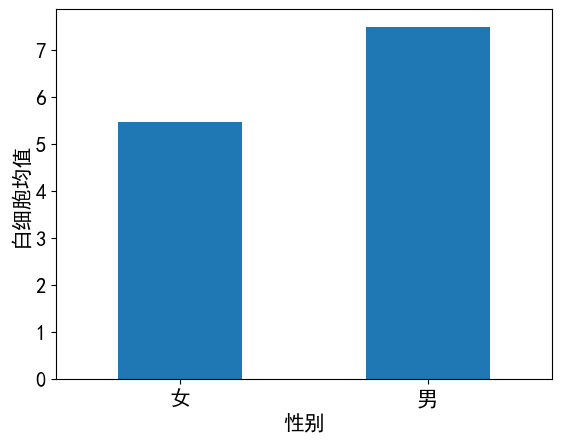

In [22]:
plt.rcParams['font.size'] = 15
plt.rcParams['font.family'] = 'SimHei'
mean.plot(kind = 'bar')
plt.xticks(rotation = 0)
plt.ylabel('白细胞均值')

In [23]:
data['年龄段'] = pd.cut(data.年龄, bins = [0,30,40,50,100])
count = data.groupby('年龄段')['白细胞计数'].mean()
count

年龄段
(0, 30]      5.943176
(30, 40]     7.492611
(40, 50]     5.478235
(50, 100]    5.734107
Name: 白细胞计数, dtype: float64

Text(0.5, 0, '年龄段')

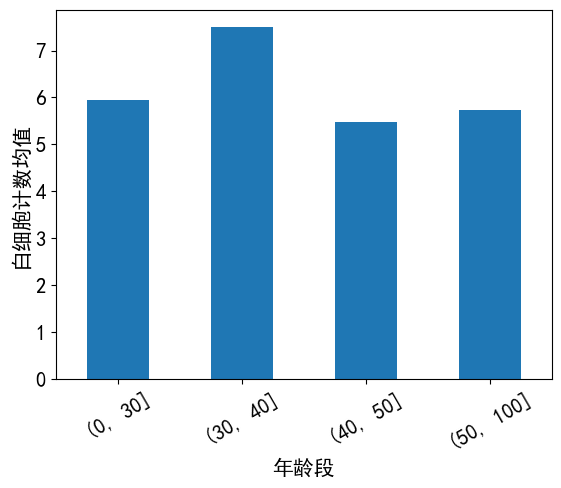

In [25]:
count.plot(kind = "bar")
plt.xticks(rotation = 30)
plt.ylabel("白细胞计数均值")
plt.xlabel('年龄段')